# Quantum Teleportation

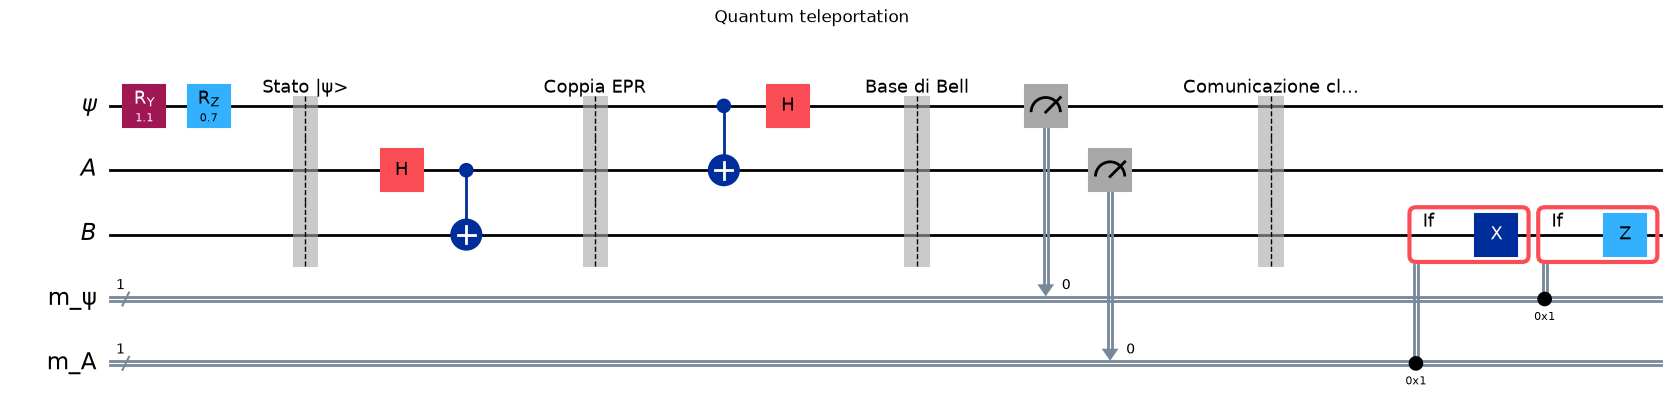

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister

PSI, A, B = 0, 1, 2

# Parametri dello stato da teletrasportare: |ψ> = Rz(phi) Ry(theta) |0>
theta, phi = 1.1, 0.7

qpsi, qA, qB = QuantumRegister(1, "ψ"), QuantumRegister(1, "A"), QuantumRegister(1, "B")
c_psi = ClassicalRegister(1, "m_ψ")
c_A = ClassicalRegister(1, "m_A")
qc = QuantumCircuit(qpsi, qA, qB, c_psi, c_A)

# 1) Preparazione dello stato da teletrasportare (Alice)
qc.ry(theta, PSI)
qc.rz(phi, PSI)
qc.barrier(label="Stato |ψ>")

# 2) Generazione della coppia EPR condivisa |Φ+> tra Alice (A) e Bob (B)
qc.h(A)
qc.cx(A, B)
qc.barrier(label="Coppia EPR")

# 3) Misura di Bell di Alice su (ψ, A)
qc.cx(PSI, A)
qc.h(PSI)
qc.barrier(label="Base di Bell")

# 4) Misure di Alice
qc.measure(PSI, c_psi)
qc.measure(A, c_A)
qc.barrier(label="Comunicazione classica")

# 5) Correzioni di Bob (feed-forward classico)
with qc.if_test((c_A, 1)):
    qc.x(B)
with qc.if_test((c_psi, 1)):
    qc.z(B)

fig = qc.draw(output="mpl", style="iqp")
fig.suptitle("Quantum teleportation")
# fig.savefig("teleportation.png", dpi=300, bbox_inches="tight")
display(fig)
plt.close(fig)